# Aula 7.4 — Exercício Guiado: Benchmark de Boosting

**XGBoost × LightGBM × CatBoost — mesmos dados, mesmas divisões e mesmas métricas.**

Este notebook reproduz a sequência prática do PDF: dataset sintético de 2.400 amostras, divisão em treino/validação/teste, baseline, treinamento dos três modelos com Early Stopping, métricas, matrizes de confusão, tempo, importância por permutação e conclusão.

> Execute em um ambiente com NumPy, Pandas, Matplotlib, Scikit-learn, XGBoost, LightGBM e CatBoost instalados. Os tempos são específicos da máquina e da execução.

## Aula 7.4 — Boosting: Xgboost, Lightgbm E Catboost

In [1]:
# AULA 7.4 — BOOSTING: XGBOOST, LIGHTGBM E CATBOOST
# EXERCÍCIO GUIADO: BENCHMARK DOS TRÊS ALGORITMOS NO MESMO SPLIT
#
# Baseado nas etapas práticas das páginas 51–67 do PDF da Aula 7.4.
# Objetivo: comparar três implementações de Gradient Boosting sob o mesmo
# dataset, as mesmas divisões, a mesma validação e as mesmas métricas.
#
# Instalação local:
#   python -m pip install numpy pandas matplotlib scikit-learn xgboost lightgbm catboost
#
# Google Colab (em uma célula separada):
#   %pip install -q xgboost lightgbm catboost

In [2]:
from __future__ import annotations

import time
import importlib.metadata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from packaging.version import Version

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier
import xgboost

from lightgbm import LGBMClassifier, early_stopping, log_evaluation
import lightgbm

from catboost import CatBoostClassifier
import catboost


# Pasta para salvar figuras e tabelas. No .py, fica ao lado do script;
# no notebook, fica dentro da pasta de trabalho atual.
try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()

OUTPUT_DIR = BASE_DIR / "resultados_aula_7_4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

np.set_printoptions(precision=4, suppress=True)

## Etapa 1 — Bibliotecas E Versões

In [3]:
# ETAPA 1 — BIBLIOTECAS E VERSÕES

In [4]:
print("\nETAPA 1 — BIBLIOTECAS E VERSÕES")

pacotes = [
    "numpy",
    "pandas",
    "matplotlib",
    "scikit-learn",
    "xgboost",
    "lightgbm",
    "catboost",
]

versoes = {}
for pacote in pacotes:
    versoes[pacote] = importlib.metadata.version(pacote)
    print(f"{pacote}: {versoes[pacote]}")

pd.Series(versoes, name="Versão").to_csv(OUTPUT_DIR / "versoes_bibliotecas.csv")


ETAPA 1 — BIBLIOTECAS E VERSÕES
numpy: 2.3.5
pandas: 2.2.3
matplotlib: 3.10.8
scikit-learn: 1.8.0
xgboost: 3.1.3
lightgbm: 4.6.0
catboost: 1.2.8


## Etapa 2 — Criação Do Dataset

In [5]:
# ETAPA 2 — CRIAÇÃO DO DATASET

In [6]:
print("\nETAPA 2 — CRIAÇÃO DO DATASET")

X, y = make_classification(
    n_samples=2400,
    n_features=16,
    n_informative=8,
    n_redundant=4,
    n_repeated=0,
    n_clusters_per_class=2,
    weights=[0.55, 0.45],
    flip_y=0.03,
    class_sep=1.0,
    random_state=42,
)

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)
print("Classes e contagens:", np.unique(y, return_counts=True))


ETAPA 2 — CRIAÇÃO DO DATASET
Formato de X: (2400, 16)
Formato de y: (2400,)
Classes e contagens: (array([0, 1]), array([1317, 1083]))


## Etapa 3 — Exploração Dos Dados

In [7]:
# ETAPA 3 — EXPLORAÇÃO DOS DADOS


ETAPA 3 — EXPLORAÇÃO DOS DADOS

Primeiras linhas:
   feature_01  feature_02  feature_03  ...  feature_15  feature_16  target
0   -1.308549    0.175379    0.477448  ...    0.844372    2.961358       0
1    0.993785    0.037318   -1.809583  ...    0.956167    0.327103       0
2   -2.021336    1.722172    0.335095  ...   -0.773936   -2.652716       1
3    1.387951    1.265122    0.264794  ...   -0.024365    2.394232       0
4    1.229089   -0.601923    1.461242  ...   -0.939817    6.393043       1

[5 rows x 17 columns]

Dimensões do DataFrame: (2400, 17)

Tipos de dados:
float64    16
int64       1
Name: count, dtype: int64

Distribuição das classes:
target
0    1317
1    1083
Name: count, dtype: int64

Distribuição proporcional:
target
0    0.54875
1    0.45125
Name: proportion, dtype: float64

Estatísticas descritivas:
             count      mean       std  ...       50%       75%        max
feature_01  2400.0 -0.012053  1.020465  ... -0.021629  0.695055   3.938503
feature_02  2400.0

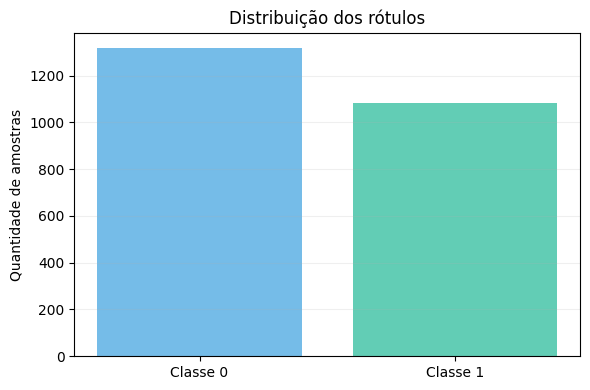

In [8]:
print("\nETAPA 3 — EXPLORAÇÃO DOS DADOS")

colunas = [f"feature_{i:02d}" for i in range(1, 17)]
df = pd.DataFrame(X, columns=colunas)
df["target"] = y

print("\nPrimeiras linhas:")
print(df.head())
print("\nDimensões do DataFrame:", df.shape)
print("\nTipos de dados:")
print(df.dtypes.value_counts())
print("\nDistribuição das classes:")
print(df["target"].value_counts().sort_index())
print("\nDistribuição proporcional:")
print(df["target"].value_counts(normalize=True).sort_index())
print("\nEstatísticas descritivas:")
print(df.describe().T)

df.head().to_csv(OUTPUT_DIR / "amostra_dataset.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 4))
contagens = df["target"].value_counts().sort_index()
ax.bar(["Classe 0", "Classe 1"], contagens.values,
       color=["#75BCE8", "#62CDB5"])
ax.set_title("Distribuição dos rótulos")
ax.set_ylabel("Quantidade de amostras")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_distribuicao_classes.png", dpi=160)
plt.show()

## Etapa 4 — Treino, Validação E Teste

In [9]:
# ETAPA 4 — TREINO, VALIDAÇÃO E TESTE

In [10]:
print("\nETAPA 4 — TREINO, VALIDAÇÃO E TESTE")

X_df = df[colunas]

X_temp, X_test, y_temp, y_test = train_test_split(
    X_df,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    stratify=y_temp,
    random_state=42,
)

print("Treino:", X_train.shape, y_train.shape)
print("Validação:", X_val.shape, y_val.shape)
print("Teste:", X_test.shape, y_test.shape)

assert len(X_train) == 1440
assert len(X_val) == 480
assert len(X_test) == 480

# Todos os modelos abaixo receberão exatamente esses mesmos conjuntos.


ETAPA 4 — TREINO, VALIDAÇÃO E TESTE
Treino: (1440, 16) (1440,)
Validação: (480, 16) (480,)
Teste: (480, 16) (480,)


## Etapa 5 — Baseline

In [11]:
# ETAPA 5 — BASELINE

In [12]:
print("\nETAPA 5 — BASELINE")

baseline = DummyClassifier(strategy="prior")

inicio = time.perf_counter()
baseline.fit(X_train, y_train)
tempo_baseline = time.perf_counter() - inicio

pred_base = baseline.predict(X_test)
acc_base = accuracy_score(y_test, pred_base)
print(f"Acurácia do baseline: {acc_base:.4f}")
print(f"Tempo de treinamento do baseline: {tempo_baseline:.4f} s")


ETAPA 5 — BASELINE
Acurácia do baseline: 0.5479
Tempo de treinamento do baseline: 0.0010 s


## Etapas 6 E 7 — Configuração E Treinamento Do Xgboost

In [13]:
# ETAPAS 6 E 7 — CONFIGURAÇÃO E TREINAMENTO DO XGBOOST

In [14]:
print("\nETAPAS 6 E 7 — XGBOOST")

modelo_xgb = XGBClassifier(
    n_estimators=800,
    max_depth=5,
    learning_rate=0.05,
    objective="binary:logistic",
    eval_metric="auc",
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    tree_method="hist",
    n_jobs=-1,
)

# A API de Early Stopping mudou entre versões do XGBoost.
# A partir de 1.6, o parâmetro deve ser configurado no estimador.
versao_xgb = Version(xgboost.__version__)
fit_extra_xgb = {}
if versao_xgb >= Version("1.6.0"):
    modelo_xgb.set_params(early_stopping_rounds=40)
else:
    fit_extra_xgb = {"early_stopping_rounds": 40}

inicio = time.perf_counter()
modelo_xgb.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
    **fit_extra_xgb,
)
tempo_xgb = time.perf_counter() - inicio

best_iteration_xgb = getattr(modelo_xgb, "best_iteration", None)
if best_iteration_xgb is None:
    arvores_xgb = modelo_xgb.n_estimators
else:
    arvores_xgb = int(best_iteration_xgb) + 1

print(f"Tempo medido do XGBoost: {tempo_xgb:.4f} s")
print("Melhor iteração do XGBoost:", best_iteration_xgb)
print("Árvores efetivamente utilizadas:", arvores_xgb)


ETAPAS 6 E 7 — XGBOOST


Tempo medido do XGBoost: 0.3820 s
Melhor iteração do XGBoost: 172
Árvores efetivamente utilizadas: 173


## Etapas 8 E 9 — Configuração E Treinamento Do Lightgbm

In [15]:
# ETAPAS 8 E 9 — CONFIGURAÇÃO E TREINAMENTO DO LIGHTGBM

In [16]:
print("\nETAPAS 8 E 9 — LIGHTGBM")

modelo_lgbm = LGBMClassifier(
    n_estimators=800,
    learning_rate=0.05,
    max_depth=5,
    num_leaves=31,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="binary",
    metric="auc",
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)

inicio = time.perf_counter()
modelo_lgbm.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="auc",
    callbacks=[
        early_stopping(40, verbose=False),
        log_evaluation(0),
    ],
)
tempo_lgbm = time.perf_counter() - inicio

best_iteration_lgbm = getattr(modelo_lgbm, "best_iteration_", None)
if best_iteration_lgbm in (None, 0):
    arvores_lgbm = modelo_lgbm.booster_.current_iteration()
else:
    arvores_lgbm = int(best_iteration_lgbm)

print(f"Tempo medido do LightGBM: {tempo_lgbm:.4f} s")
print("Melhor iteração do LightGBM:", best_iteration_lgbm)
print("Árvores efetivamente utilizadas:", arvores_lgbm)


ETAPAS 8 E 9 — LIGHTGBM


Tempo medido do LightGBM: 0.2798 s
Melhor iteração do LightGBM: 288
Árvores efetivamente utilizadas: 288


## Etapas 10 E 11 — Configuração E Treinamento Do Catboost

In [17]:
# ETAPAS 10 E 11 — CONFIGURAÇÃO E TREINAMENTO DO CATBOOST

In [18]:
print("\nETAPAS 10 E 11 — CATBOOST")

modelo_cat = CatBoostClassifier(
    iterations=800,
    depth=5,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    l2_leaf_reg=3.0,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1,
)

inicio = time.perf_counter()
modelo_cat.fit(
    X_train,
    y_train,
    eval_set=(X_val, y_val),
    early_stopping_rounds=40,
    verbose=False,
)
tempo_cat = time.perf_counter() - inicio

arvores_cat = modelo_cat.tree_count_
best_iteration_cat = getattr(modelo_cat, "best_iteration_", None)

print(f"Tempo medido do CatBoost: {tempo_cat:.4f} s")
print("Melhor iteração do CatBoost:", best_iteration_cat)
print("Árvores efetivamente utilizadas:", arvores_cat)


ETAPAS 10 E 11 — CATBOOST


Tempo medido do CatBoost: 0.5770 s
Melhor iteração do CatBoost: 151
Árvores efetivamente utilizadas: 152


## Etapa 12 — Conferência Da Comparação Justa

In [19]:
# ETAPA 12 — CONFERÊNCIA DA COMPARAÇÃO JUSTA

In [20]:
print("\nETAPA 12 — CONFERÊNCIA DA COMPARAÇÃO JUSTA")

assert set(X_train.index).isdisjoint(set(X_val.index))
assert set(X_train.index).isdisjoint(set(X_test.index))
assert set(X_val.index).isdisjoint(set(X_test.index))
assert len(X_train) == 1440 and len(X_val) == 480 and len(X_test) == 480
assert len(y_train) == 1440 and len(y_val) == 480 and len(y_test) == 480
assert set(np.unique(y_train)) == {0, 1}
assert set(np.unique(y_val)) == {0, 1}
assert set(np.unique(y_test)) == {0, 1}

print("OK: mesmo dataset, mesmos conjuntos, mesmos rótulos e mesma métrica de avaliação (AUC).")
print("Observação: os hiperparâmetros internos não são perfeitamente equivalentes entre as bibliotecas.")
print("Este benchmark compara configurações documentadas sob o mesmo protocolo; não prova superioridade universal.")


ETAPA 12 — CONFERÊNCIA DA COMPARAÇÃO JUSTA
OK: mesmo dataset, mesmos conjuntos, mesmos rótulos e mesma métrica de avaliação (AUC).
Observação: os hiperparâmetros internos não são perfeitamente equivalentes entre as bibliotecas.
Este benchmark compara configurações documentadas sob o mesmo protocolo; não prova superioridade universal.


## Etapas 13 E 14 — Probabilidades E Limiar Comum

In [21]:
# ETAPAS 13 E 14 — PROBABILIDADES E LIMIAR COMUM

In [22]:
print("\nETAPAS 13 E 14 — PROBABILIDADES E LIMIAR COMUM")


def probabilidade_classe_positiva(modelo, X_entrada):
    """Retorna a coluna de predict_proba correspondente à classe 1."""
    probabilidades = modelo.predict_proba(X_entrada)
    indice_positivo = list(modelo.classes_).index(1)
    return probabilidades[:, indice_positivo]


LIMIAR = 0.5
modelos = {
    "XGBoost": modelo_xgb,
    "LightGBM": modelo_lgbm,
    "CatBoost": modelo_cat,
}

tempos = {
    "Baseline": tempo_baseline,
    "XGBoost": tempo_xgb,
    "LightGBM": tempo_lgbm,
    "CatBoost": tempo_cat,
}

proba_teste = {
    "Baseline": probabilidade_classe_positiva(baseline, X_test),
}
pred_teste = {
    "Baseline": (proba_teste["Baseline"] >= LIMIAR).astype(int),
}

for nome, modelo in modelos.items():
    p = probabilidade_classe_positiva(modelo, X_test)
    proba_teste[nome] = p
    pred_teste[nome] = (p >= LIMIAR).astype(int)

print("Probabilidades e previsões calculadas para todos os modelos.")
print("Limiar comum:", LIMIAR)


ETAPAS 13 E 14 — PROBABILIDADES E LIMIAR COMUM
Probabilidades e previsões calculadas para todos os modelos.
Limiar comum: 0.5


## Etapa 15 — Métricas Comuns

In [23]:
# ETAPA 15 — MÉTRICAS COMUNS

In [24]:
print("\nETAPA 15 — MÉTRICAS COMUNS")


def calcular_metricas(nome, y_true, proba, tempo=np.nan):
    """Calcula métricas de classe e de probabilidade com limiar comum."""
    pred = (proba >= LIMIAR).astype(int)
    return {
        "Modelo": nome,
        "Acurácia": accuracy_score(y_true, pred),
        "Precisão": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_true, proba),
        "Log Loss": log_loss(y_true, proba, labels=[0, 1]),
        "Tempo (s)": tempo,
    }


resultados = []
for nome in ["Baseline", "XGBoost", "LightGBM", "CatBoost"]:
    resultados.append(
        calcular_metricas(nome, y_test, proba_teste[nome], tempos[nome])
    )

df_metricas = pd.DataFrame(resultados)
print(df_metricas.to_string(index=False, float_format=lambda valor: f"{valor:.4f}"))
df_metricas.to_csv(OUTPUT_DIR / "tabela_metricas_teste.csv", index=False)


ETAPA 15 — MÉTRICAS COMUNS
  Modelo  Acurácia  Precisão  Recall     F1  ROC AUC  Log Loss  Tempo (s)
Baseline    0.5479    0.0000  0.0000 0.0000   0.5000    0.6885     0.0010
 XGBoost    0.8938    0.9029  0.8571 0.8794   0.9641    0.2461     0.3820
LightGBM    0.9083    0.9261  0.8664 0.8952   0.9663    0.2332     0.2798
CatBoost    0.9062    0.9019  0.8894 0.8956   0.9705    0.2511     0.5770


## Etapa 16 — Matrizes De Confusão

In [25]:
# ETAPA 16 — MATRIZES DE CONFUSÃO


ETAPA 16 — MATRIZES DE CONFUSÃO


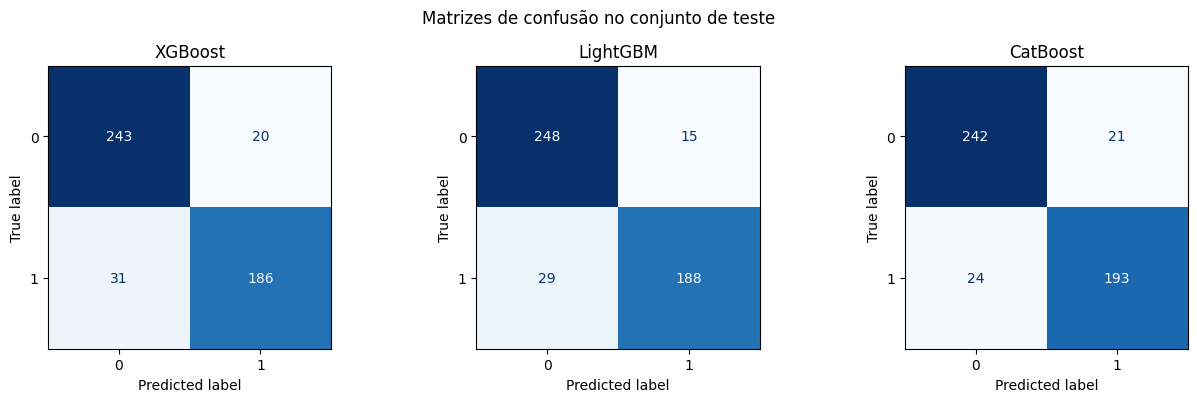

In [26]:
print("\nETAPA 16 — MATRIZES DE CONFUSÃO")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, nome in zip(axes, ["XGBoost", "LightGBM", "CatBoost"]):
    cm = confusion_matrix(y_test, pred_teste[nome], labels=[0, 1])
    disp = ConfusionMatrixDisplay(cm, display_labels=[0, 1])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nome)
fig.suptitle("Matrizes de confusão no conjunto de teste")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_matrizes_confusao.png", dpi=160)
plt.show()

## Etapa 17 — Tabela Comparativa No Teste

In [27]:
# ETAPA 17 — TABELA COMPARATIVA NO TESTE

In [28]:
print("\nETAPA 17 — TABELA COMPARATIVA NO TESTE")

print("\nVersões utilizadas:")
for pacote, versao in versoes.items():
    print(f"{pacote}: {versao}")

print("\nTabela final:")
print(df_metricas.to_string(index=False, float_format=lambda valor: f"{valor:.4f}"))


ETAPA 17 — TABELA COMPARATIVA NO TESTE

Versões utilizadas:
numpy: 2.3.5
pandas: 2.2.3
matplotlib: 3.10.8
scikit-learn: 1.8.0
xgboost: 3.1.3
lightgbm: 4.6.0
catboost: 1.2.8

Tabela final:
  Modelo  Acurácia  Precisão  Recall     F1  ROC AUC  Log Loss  Tempo (s)
Baseline    0.5479    0.0000  0.0000 0.0000   0.5000    0.6885     0.0010
 XGBoost    0.8938    0.9029  0.8571 0.8794   0.9641    0.2461     0.3820
LightGBM    0.9083    0.9261  0.8664 0.8952   0.9663    0.2332     0.2798
CatBoost    0.9062    0.9019  0.8894 0.8956   0.9705    0.2511     0.5770


## Etapa 18 — Tempo De Treinamento

In [29]:
# ETAPA 18 — TEMPO DE TREINAMENTO


ETAPA 18 — TEMPO DE TREINAMENTO


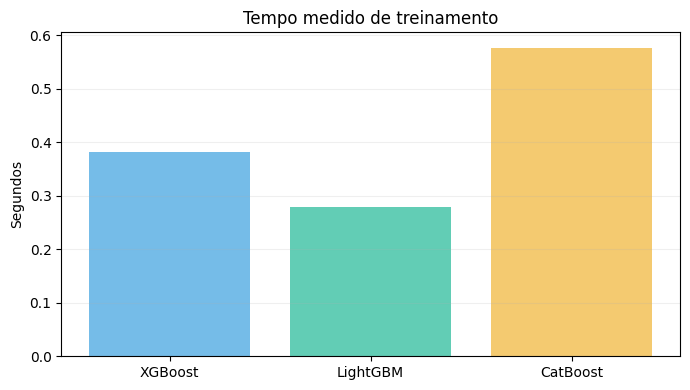

Tempos de treinamento (s):
XGBoost: 0.3820
LightGBM: 0.2798
CatBoost: 0.5770
Árvores/iterações efetivamente utilizadas:
{'XGBoost': 173, 'LightGBM': 288, 'CatBoost': 152}


In [30]:
print("\nETAPA 18 — TEMPO DE TREINAMENTO")

nomes_tempo = ["XGBoost", "LightGBM", "CatBoost"]
valores_tempo = [tempo_xgb, tempo_lgbm, tempo_cat]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(nomes_tempo, valores_tempo,
       color=["#75BCE8", "#62CDB5", "#F4CA70"])
ax.set_title("Tempo medido de treinamento")
ax.set_ylabel("Segundos")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_tempo_treinamento.png", dpi=160)
plt.show()

print("Tempos de treinamento (s):")
for nome, valor in zip(nomes_tempo, valores_tempo):
    print(f"{nome}: {valor:.4f}")

print("Árvores/iterações efetivamente utilizadas:")
print({
    "XGBoost": arvores_xgb,
    "LightGBM": arvores_lgbm,
    "CatBoost": arvores_cat,
})

## Etapa 19 — Importância Por Permutação

In [31]:
# ETAPA 19 — IMPORTÂNCIA POR PERMUTAÇÃO


ETAPA 19 — IMPORTÂNCIA POR PERMUTAÇÃO



XGBoost — maiores importâncias por permutação:
feature_05    0.075235
feature_10    0.053946
feature_11    0.047759
feature_04    0.037226
feature_08    0.025582
feature_09    0.020462
feature_14    0.014040
feature_16    0.013093
feature_03    0.012202
feature_06    0.007860
dtype: float64



LightGBM — maiores importâncias por permutação:
feature_05    0.080671
feature_10    0.048583
feature_11    0.041407
feature_09    0.028598
feature_04    0.025305
feature_08    0.022755
feature_03    0.022320
feature_14    0.017116
feature_16    0.013801
feature_13    0.009968
dtype: float64



CatBoost — maiores importâncias por permutação:
feature_05    0.069627
feature_10    0.056969
feature_11    0.050042
feature_08    0.032804
feature_03    0.029233
feature_09    0.028756
feature_04    0.024600
feature_14    0.014846
feature_06    0.010076
feature_16    0.007085
dtype: float64


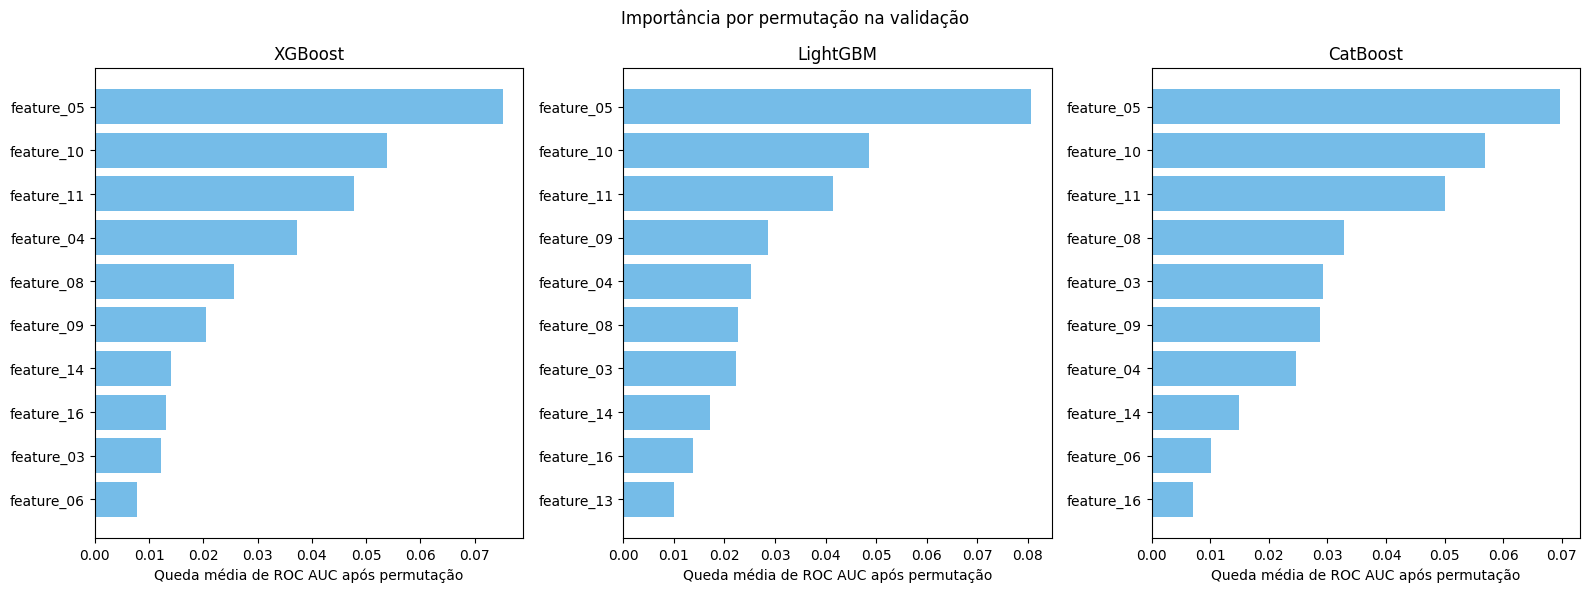

Observação: a importância não significa causalidade. A validação também foi usada para early stopping; portanto, esta análise é exploratória.


In [32]:
print("\nETAPA 19 — IMPORTÂNCIA POR PERMUTAÇÃO")


def auc_validacao(modelo, X_avaliacao, y_avaliacao):
    """Scorer compatível com permutation_importance: (estimador, X, y)."""
    proba = probabilidade_classe_positiva(modelo, X_avaliacao)
    return roc_auc_score(y_avaliacao, proba)


importancias = {}
for nome, modelo in modelos.items():
    resultado = permutation_importance(
        modelo,
        X_val,
        y_val,
        scoring=auc_validacao,
        n_repeats=5,
        random_state=42,
        n_jobs=1,
    )
    importancias[nome] = resultado.importances_mean

    print(f"\n{nome} — maiores importâncias por permutação:")
    ranking = pd.Series(resultado.importances_mean, index=colunas)
    print(ranking.sort_values(ascending=False).head(10))

fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharex=False)
for ax, nome in zip(axes, ["XGBoost", "LightGBM", "CatBoost"]):
    ranking = pd.Series(importancias[nome], index=colunas).sort_values().tail(10)
    ax.barh(ranking.index, ranking.values, color="#75BCE8")
    ax.set_title(nome)
    ax.set_xlabel("Queda média de ROC AUC após permutação")
fig.suptitle("Importância por permutação na validação")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_importancia_permutacao.png", dpi=160)
plt.show()

print("Observação: a importância não significa causalidade. A validação também foi usada para early stopping; portanto, esta análise é exploratória.")

## Etapa 20 — Conclusão Do Benchmark

In [33]:
# ETAPA 20 — CONCLUSÃO DO BENCHMARK

In [34]:
print("\nETAPA 20 — CONCLUSÃO DO BENCHMARK")

# Direções corretas das métricas: ROC AUC/F1/Accuracy maiores são melhores;
# Log Loss e tempo menores são melhores.
# O baseline é uma referência simples; não o incluímos na disputa entre
# as três implementações de Boosting.
df_boosting = df_metricas[df_metricas["Modelo"].isin(modelos.keys())].copy()
melhor_auc = df_boosting.loc[df_boosting["ROC AUC"].idxmax(), "Modelo"]
melhor_f1 = df_boosting.loc[df_boosting["F1"].idxmax(), "Modelo"]
menor_logloss = df_boosting.loc[df_boosting["Log Loss"].idxmin(), "Modelo"]
menor_tempo = df_boosting.loc[df_boosting["Tempo (s)"].idxmin(), "Modelo"]

print("Melhor ROC AUC entre os três modelos:", melhor_auc)
print("Melhor F1 entre os três modelos:", melhor_f1)
print("Menor Log Loss entre os três modelos:", menor_logloss)
print("Menor tempo de treinamento entre os três modelos:", menor_tempo)

# Gap de ROC AUC treino - validação: indicador descritivo para discussão.
linhas_gap = []
for nome, modelo in modelos.items():
    auc_treino = roc_auc_score(
        y_train, probabilidade_classe_positiva(modelo, X_train)
    )
    auc_validacao = roc_auc_score(
        y_val, probabilidade_classe_positiva(modelo, X_val)
    )
    linhas_gap.append({
        "Modelo": nome,
        "ROC AUC treino": auc_treino,
        "ROC AUC validação": auc_validacao,
        "Gap treino - validação": auc_treino - auc_validacao,
    })

df_gap = pd.DataFrame(linhas_gap)
print("\nGap de ROC AUC entre treino e validação:")
print(df_gap.to_string(index=False, float_format=lambda valor: f"{valor:.4f}"))
df_gap.to_csv(OUTPUT_DIR / "gap_treino_validacao.csv", index=False)

# Concordância das importâncias por permutação: correlação de Spearman
# entre os rankings das 16 características.
df_importancias = pd.DataFrame(importancias, index=colunas)
correlacao_importancias = df_importancias.corr(method="spearman")
print("\nCorrelação de Spearman entre rankings de importância:")
print(correlacao_importancias.to_string(float_format=lambda valor: f"{valor:.3f}"))
correlacao_importancias.to_csv(OUTPUT_DIR / "correlacao_importancias.csv")

print("\nLimitações do experimento:")
print("- Dataset sintético e um único split.")
print("- Hiperparâmetros específicos, não equivalentes internamente.")
print("- Tempos de uma execução nesta máquina.")
print("- Pequenas diferenças podem mudar com outra semente ou hardware.")
print("- Este resultado não comprova superioridade universal de uma biblioteca.")

resumo = pd.DataFrame({
    "Critério": ["Melhor ROC AUC", "Melhor F1", "Menor Log Loss", "Menor tempo entre Boosting"],
    "Modelo": [melhor_auc, melhor_f1, menor_logloss, menor_tempo],
})
resumo.to_csv(OUTPUT_DIR / "resumo_conclusao.csv", index=False)


ETAPA 20 — CONCLUSÃO DO BENCHMARK
Melhor ROC AUC entre os três modelos: CatBoost
Melhor F1 entre os três modelos: CatBoost
Menor Log Loss entre os três modelos: LightGBM
Menor tempo de treinamento entre os três modelos: LightGBM

Gap de ROC AUC entre treino e validação:
  Modelo  ROC AUC treino  ROC AUC validação  Gap treino - validação
 XGBoost          0.9997             0.9592                  0.0404
LightGBM          1.0000             0.9602                  0.0398
CatBoost          0.9937             0.9662                  0.0274

Correlação de Spearman entre rankings de importância:
          XGBoost  LightGBM  CatBoost
XGBoost     1.000     0.976     0.953
LightGBM    0.976     1.000     0.965
CatBoost    0.953     0.965     1.000

Limitações do experimento:
- Dataset sintético e um único split.
- Hiperparâmetros específicos, não equivalentes internamente.
- Tempos de uma execução nesta máquina.
- Pequenas diferenças podem mudar com outra semente ou hardware.
- Este resultado

## Exemplo Complementar — Catboost Com Características Categóricas

In [35]:
# EXEMPLO COMPLEMENTAR — CATBOOST COM CARACTERÍSTICAS CATEGÓRICAS
# Corresponde à página 67 do PDF. É uma demonstração separada do benchmark.

In [36]:
print("\nEXEMPLO COMPLEMENTAR — CATBOOST COM CARACTERÍSTICAS CATEGÓRICAS")

rng = np.random.default_rng(42)
n_cat = 360
idade = rng.integers(18, 70, size=n_cat)
plano = rng.choice(["Básico", "Padrão", "Premium"], size=n_cat)
regiao = rng.choice(["Norte", "Sul", "Leste"], size=n_cat)

# Rótulo sintético para demonstrar o fluxo, não representa um fenômeno real.
score_cat = (
    0.025 * (idade - 40)
    + 0.9 * (plano == "Premium")
    + 0.25 * (plano == "Padrão")
    + 0.35 * (regiao == "Norte")
    + rng.normal(0, 0.65, size=n_cat)
)
compra = (score_cat > 0.45).astype(int)

df_cat = pd.DataFrame({
    "idade": idade,
    "plano": plano,
    "regiao": regiao,
})
y_cat = compra

Xc_train, Xc_val, yc_train, yc_val = train_test_split(
    df_cat,
    y_cat,
    test_size=0.25,
    stratify=y_cat,
    random_state=42,
)

colunas_cat = ["plano", "regiao"]
modelo_cat_demo = CatBoostClassifier(
    iterations=300,
    depth=4,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1,
)

modelo_cat_demo.fit(
    Xc_train,
    yc_train,
    cat_features=colunas_cat,
    eval_set=(Xc_val, yc_val),
    early_stopping_rounds=30,
    verbose=False,
)

proba_cat_demo = modelo_cat_demo.predict_proba(Xc_val)[:, 1]
print("AUC de validação do exemplo categórico:", roc_auc_score(yc_val, proba_cat_demo))
print("Características categóricas utilizadas:", colunas_cat)

print("\nEXERCÍCIO CONCLUÍDO.")
print("Arquivos de resultados salvos em:", OUTPUT_DIR.resolve())


EXEMPLO COMPLEMENTAR — CATBOOST COM CARACTERÍSTICAS CATEGÓRICAS
AUC de validação do exemplo categórico: 0.8291170634920635
Características categóricas utilizadas: ['plano', 'regiao']

EXERCÍCIO CONCLUÍDO.
Arquivos de resultados salvos em: /mnt/data/resultados_aula_7_4
